# <center>Test</center>

---
## 1. Data loading

In [4]:
#autoreload all the modules
#If an error occurs after importing a module, re-executing these statements should resolve the issue.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import glob
import pandas as pd
import re

#beacuse of k-nn
from warnings import simplefilter
simplefilter(action='ignore', category = FutureWarning)

#Numpy version check
import numpy as np
np.__version__
#delete the comment before pip if the version is not 1.21.4
#pip install --upgrade numpy==1.21.4 --user

'1.21.4'

In [5]:
from Modules import data_manipulation_module as dmm

In [6]:
#Detection data loading and preparation
Detection_csv_files = glob.glob('/tf/notebooks/TestDatasCSV/Detection_data/*.csv')
Detection_csv_files = sorted(Detection_csv_files, key = lambda detection: list(map(int, re.findall("\d+", detection))))

Detection_col_names = ['Timestamp', 'Posture_12_X', 'Posture_12_Y', 'Posture_14_X', 'Posture_14_Y', 'Master_X_left', 'Master_Y_left', 'Master_Z_left', 'Master_X_right', 'Master_Y_right', 'Master_Z_right', 'HR']
Detection_df_list = dmm.Loading_data(Detection_csv_files, ",", Detection_col_names)

#Drop: Timestamp column 
for i in range(len(Detection_df_list)):
    Detection_df_list[i] = Detection_df_list[i].drop(['Timestamp'], axis=1)

In [8]:
Questionnaire = dmm.Loading_data('/tf/notebooks/TestDatasCSV/Questionnarie.csv', ";", None)

In [9]:
#def Multi_class_target_variable(df_class_value, class_tresholds):
    #Selecting the SURG-TLX questions as the target variable (binary classification)
    #If the value is below mean of that question, the participant is classified as 0, indicating the novice class
    #Conversely, the participant is 1, indicating the expert class
Questionnaire = dmm.Multi_target_variable(Questionnaire, [3, 4, 5, 6, 7, 8])

### Invalid numbers

In [10]:
threshold = 1e100 

for i, df in enumerate(Detection_df_list):
    where_large = np.where(df > threshold)
    for row, col in zip(*where_large):
        print(f"DF index {i}, sor {row}, oszlop {df.columns[col]} -> érték: {df.iat[row, col]}")

DF index 43, sor 2656, oszlop Master_Z_left -> érték: 2.7873250512204663e+179


In [11]:
Detection_df_list[43].iloc[2650:2670, 6]

2650    8.341768e-312
2651    8.341768e-312
2652    8.341768e-312
2653    8.341767e-312
2654    8.341767e-312
2655    8.341768e-312
2656    2.787325e+179
2657    1.397376e-259
2658     0.000000e+00
2659    8.341769e-312
2660    8.341769e-312
2661    8.341769e-312
2662    8.341769e-312
2663    8.341769e-312
2664    8.341769e-312
2665    8.341767e-312
2666    8.341767e-312
2667    8.341769e-312
2668    8.341767e-312
2669    8.341767e-312
Name: Master_Z_left, dtype: float64

In [12]:
print(Detection_df_list[43].iloc[2656,6])
Detection_df_list[43].iloc[2656,6] = 0
print(Detection_df_list[43].iloc[2656,6])

2.7873250512204663e+179
0.0


---
# 2. Approximate Entropy (ApEn)

In [14]:
feature_names = Detection_df_list[0].columns    
Detection_ApEn = pd.DataFrame(columns = feature_names)
Detection_ApEn

,Posture_12_X,Posture_12_Y,Posture_14_X,Posture_14_Y,Master_X_left,Master_Y_left,Master_Z_left,Master_X_right,Master_Y_right,Master_Z_right,HR


In [18]:
Detection_ApEn = dmm.Approximate_entropy(Detection_df_list, Detection_ApEn)

In [19]:
Detection_ApEn

,Posture_12_X,Posture_12_Y,Posture_14_X,Posture_14_Y,Master_X_left,Master_Y_left,Master_Z_left,Master_X_right,Master_Y_right,Master_Z_right,HR
0,0.173257,0.411196,0.137212,0.144918,0.083263,0.186071,0.131609,0.152999,0.270425,0.367147,0.141337
1,0.193924,0.389697,0.179736,0.272725,0.075300,0.243191,0.115800,0.196919,0.334522,0.309923,0.015554
2,0.220909,0.173628,0.236852,0.172369,0.131456,0.205356,0.173316,0.158406,0.234942,0.165652,0.023219
3,0.556840,0.117386,0.148615,0.167217,0.153755,0.581724,0.193835,0.369872,0.419896,0.537814,0.104239
4,0.634425,0.663875,0.512150,0.418960,0.113640,0.269013,0.173979,0.172892,0.271714,0.303011,0.016420
5,0.532384,1.036850,0.467986,0.478014,0.183345,0.455758,0.278992,0.546272,0.365952,0.342782,0.138998
6,0.384914,0.678897,0.637916,0.595673,0.068314,0.339246,0.084711,0.121461,0.208877,0.324081,0.112129
7,0.423378,0.531506,0.643114,0.534604,0.030474,0.255817,0.080440,0.139996,0.302841,0.422302,0.018854
8,0.418960,0.243842,0.362841,0.437527,0.079193,0.458715,0.132394,0.261129,0.210744,0.342290,0.142618
9,0.401952,0.662127,0.401040,0.666929,0.349957,0.710732,0.354652,0.331517,0.409956,0.389422,0.151073


In [21]:
Detection_mf_ApEn = dmm.Target_append(Questionnaire, Detection_ApEn, 'Mental_fatigue_of_the_task')
Detection_pf_ApEn = dmm.Target_append(Questionnaire, Detection_ApEn, 'Physical_fatigue_of_the_task')
Detection_td_ApEn = dmm.Target_append(Questionnaire, Detection_ApEn, 'Temporal_demands')
Detection_c_ApEn = dmm.Target_append(Questionnaire, Detection_ApEn, 'Complexity_of_the_task')
Detection_ss_ApEn = dmm.Target_append(Questionnaire, Detection_ApEn, 'Situational_stress')
Detection_d_ApEn = dmm.Target_append(Questionnaire, Detection_ApEn, 'Distractions')

In [22]:
Detection_mf_ApEn

,Posture_12_X,Posture_12_Y,Posture_14_X,Posture_14_Y,Master_X_left,Master_Y_left,Master_Z_left,Master_X_right,Master_Y_right,Master_Z_right,HR,Mental_fatigue_of_the_task
0,0.173257,0.411196,0.137212,0.144918,0.083263,0.186071,0.131609,0.152999,0.270425,0.367147,0.141337,1
1,0.193924,0.389697,0.179736,0.272725,0.075300,0.243191,0.115800,0.196919,0.334522,0.309923,0.015554,0
2,0.220909,0.173628,0.236852,0.172369,0.131456,0.205356,0.173316,0.158406,0.234942,0.165652,0.023219,1
3,0.556840,0.117386,0.148615,0.167217,0.153755,0.581724,0.193835,0.369872,0.419896,0.537814,0.104239,1
4,0.634425,0.663875,0.512150,0.418960,0.113640,0.269013,0.173979,0.172892,0.271714,0.303011,0.016420,0
5,0.532384,1.036850,0.467986,0.478014,0.183345,0.455758,0.278992,0.546272,0.365952,0.342782,0.138998,0
6,0.384914,0.678897,0.637916,0.595673,0.068314,0.339246,0.084711,0.121461,0.208877,0.324081,0.112129,0
7,0.423378,0.531506,0.643114,0.534604,0.030474,0.255817,0.080440,0.139996,0.302841,0.422302,0.018854,0
8,0.418960,0.243842,0.362841,0.437527,0.079193,0.458715,0.132394,0.261129,0.210744,0.342290,0.142618,0
9,0.401952,0.662127,0.401040,0.666929,0.349957,0.710732,0.354652,0.331517,0.409956,0.389422,0.151073,0


---
# 3. Train-test dataset

In [23]:
Detection_mf_X_ApEn, Detection_mf_Y_ApEn = dmm.Features_target(Detection_mf_ApEn)
Detection_pf_X_ApEn, Detection_pf_Y_ApEn = dmm.Features_target(Detection_pf_ApEn)
Detection_td_X_ApEn, Detection_td_Y_ApEn = dmm.Features_target(Detection_td_ApEn)
Detection_c_X_ApEn, Detection_c_Y_ApEn = dmm.Features_target(Detection_c_ApEn)
Detection_ss_X_ApEn, Detection_ss_Y_ApEn = dmm.Features_target(Detection_ss_ApEn)
Detection_d_X_ApEn, Detection_d_Y_ApEn = dmm.Features_target(Detection_d_ApEn)

In [25]:
Detection_mf_Y_ApEn

array([1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 1, 1])

In [26]:
Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn = dmm.Train_test(Detection_mf_X_ApEn, Detection_mf_Y_ApEn, 0.3)
Detection_pf_X_train_ApEn, Detection_pf_X_test_ApEn, Detection_pf_Y_train_ApEn, Detection_pf_Y_test_ApEn = dmm.Train_test(Detection_pf_X_ApEn, Detection_pf_Y_ApEn, 0.3)
Detection_td_X_train_ApEn, Detection_td_X_test_ApEn, Detection_td_Y_train_ApEn, Detection_td_Y_test_ApEn = dmm.Train_test(Detection_td_X_ApEn, Detection_td_Y_ApEn, 0.3)
Detection_c_X_train_ApEn, Detection_c_X_test_ApEn, Detection_c_Y_train_ApEn, Detection_c_Y_test_ApEn = dmm.Train_test(Detection_c_X_ApEn, Detection_c_Y_ApEn, 0.3)
Detection_ss_X_train_ApEn, Detection_ss_X_test_ApEn, Detection_ss_Y_train_ApEn, Detection_ss_Y_test_ApEn = dmm.Train_test(Detection_ss_X_ApEn, Detection_ss_Y_ApEn, 0.3)
Detection_d_X_train_ApEn, Detection_d_X_test_ApEn, Detection_d_Y_train_ApEn, Detection_d_Y_test_ApEn = dmm.Train_test(Detection_d_X_ApEn, Detection_d_Y_ApEn, 0.3)

In [30]:
Detection_mf_Y_train_ApEn

array([1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1])

In [31]:
Detection_mf_Y_test_ApEn

array([0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1])

---
# 4. Standardization

In [29]:
Detection_standardized_mf_X_train_ApEn, Detection_standardized_mf_X_test_ApEn = dmm.Standardization(Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn)
Detection_standardized_pf_X_train_ApEn, Detection_standardized_pf_X_test_ApEn = dmm.Standardization(Detection_pf_X_train_ApEn, Detection_pf_X_test_ApEn)
Detection_standardized_td_X_train_ApEn, Detection_standardized_td_X_test_ApEn = dmm.Standardization(Detection_td_X_train_ApEn, Detection_td_X_test_ApEn)
Detection_standardized_c_X_train_ApEn, Detection_standardized_c_X_test_ApEn = dmm.Standardization(Detection_c_X_train_ApEn, Detection_c_X_test_ApEn)
Detection_standardized_ss_X_train_ApEn, Detection_standardized_ss_X_test_ApEn = dmm.Standardization(Detection_ss_X_train_ApEn, Detection_ss_X_test_ApEn)
Detection_standardized_d_X_train_ApEn, Detection_standardized_d_X_test_ApEn = dmm.Standardization(Detection_d_X_train_ApEn, Detection_d_X_test_ApEn)

---
# 5. Decision Tree
### 5.1. Model creation and traning-testing

In [25]:
%set_env TF_ENABLE_ONEDNN_OPTS=0

from Modules import nts_classification_algorithms_module as nts_cam
from Modules import validation_and_results_module as vrm
from Modules import plots_module as pm

env: TF_ENABLE_ONEDNN_OPTS=0


In [33]:
#Decision_tree(criterion, splitter, max_depth, max_features)
DT_model_ApEn_binary = nts_cam.Decision_tree("entropy", "random", 5, 5)
DT_standardized_model_ApEn_binary = nts_cam.Decision_tree("entropy", "random", 5, 5)

DT_model_ApEn_binary

DecisionTreeClassifier(criterion='entropy', max_depth=5, max_features=5,
                       random_state=0, splitter='random')

In [35]:
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(DT_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [1 0 0 0 0 0 0 0 0 0 0 1 0 1 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.80      0.73        10
           1       0.33      0.20      0.25         5

    accuracy                           0.60        15
   macro avg       0.50      0.50      0.49        15
weighted avg       0.56      0.60      0.57        15



In [36]:
vrm.Model_classification_report(DT_standardized_model_ApEn_binary, Detection_standardized_mf_X_train_ApEn, Detection_standardized_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [1 0 0 0 0 0 0 0 0 0 0 1 0 1 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.80      0.73        10
           1       0.33      0.20      0.25         5

    accuracy                           0.60        15
   macro avg       0.50      0.50      0.49        15
weighted avg       0.56      0.60      0.57        15



### 5.2. Results checking

In [37]:
from sklearn.tree import DecisionTreeClassifier

In [38]:
model = DecisionTreeClassifier(criterion="entropy", max_depth=5, max_features=5, random_state=0, splitter="random")
model.fit(Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn)
model.score(Detection_mf_X_test_ApEn, Detection_mf_Y_test_ApEn)

0.6

### 5.3. DT visualization

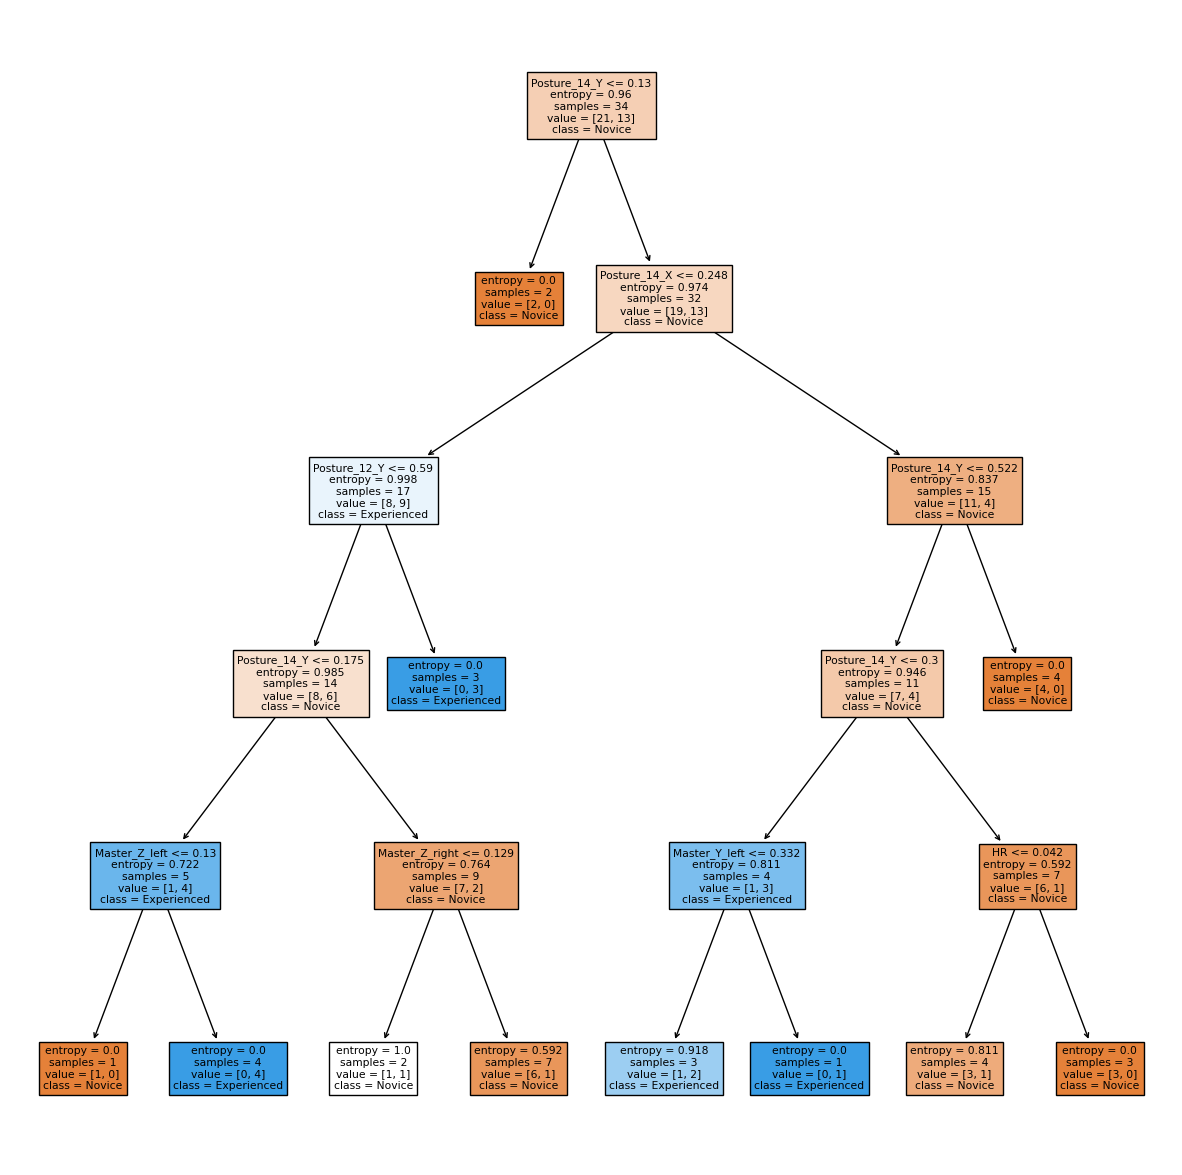

In [39]:
#Decision_tree_visualization(class_names, model, feature_names, fig_size)
pm.Decision_tree_visualization(["Novice", "Experienced"], DT_model_ApEn_binary, feature_names, (15,15))

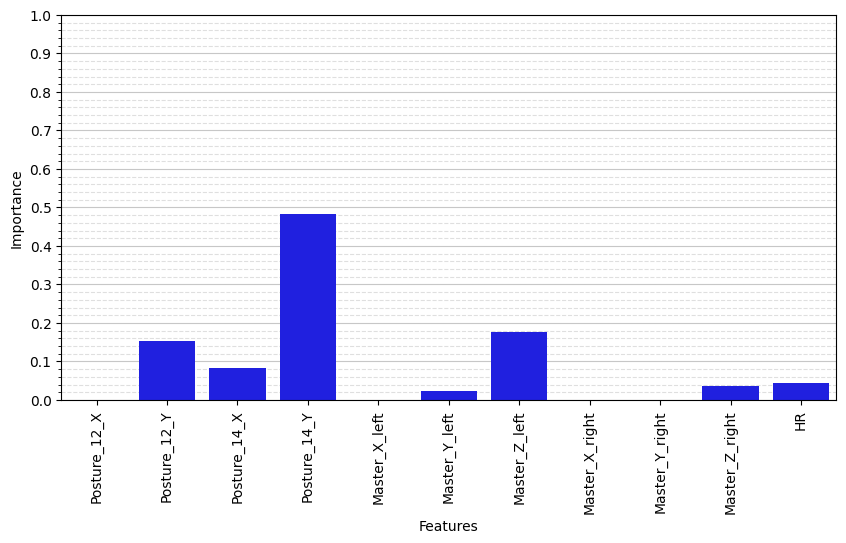

In [40]:
#Decision_tree_feature_importance(model, features, bar_color, fig_size, sort, only_not_null, vertical)
pm.Decision_tree_feature_importance(DT_model_ApEn_binary, feature_names, "blue", (10,5), False, False, True)

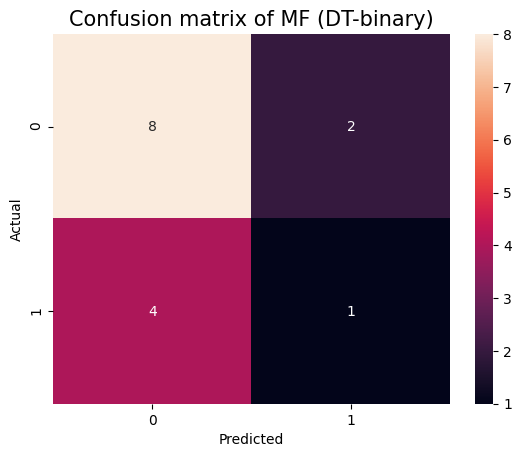

In [41]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of MF (DT-binary)", DT_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

### Picture for my thesis

In [32]:
x_train, x_test, y_train, y_test = dmm.Train_test(Detection_pf_X_ApEn, Detection_pf_Y_ApEn, 0.1)
DT_test = nts_cam.Decision_tree("entropy", "random", 5, 5)
vrm.Model_classification_report(DT_test, x_train, x_test, y_train, y_test)

Actual classes: [0 0 1 0 0], Predicted classes: [1 1 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.50      0.57         4
           1       0.00      0.00      0.00         1

    accuracy                           0.40         5
   macro avg       0.33      0.25      0.29         5
weighted avg       0.53      0.40      0.46         5



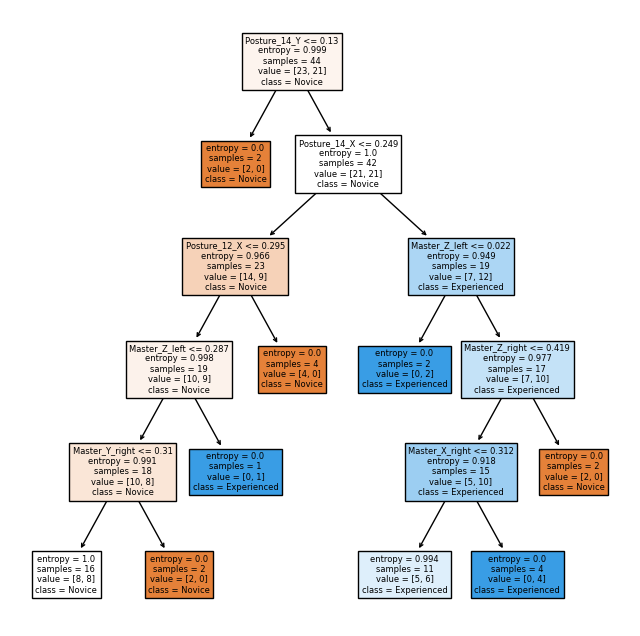

In [33]:
pm.Decision_tree_visualization(["Novice", "Experienced"], DT_test, feature_names, (8,8))

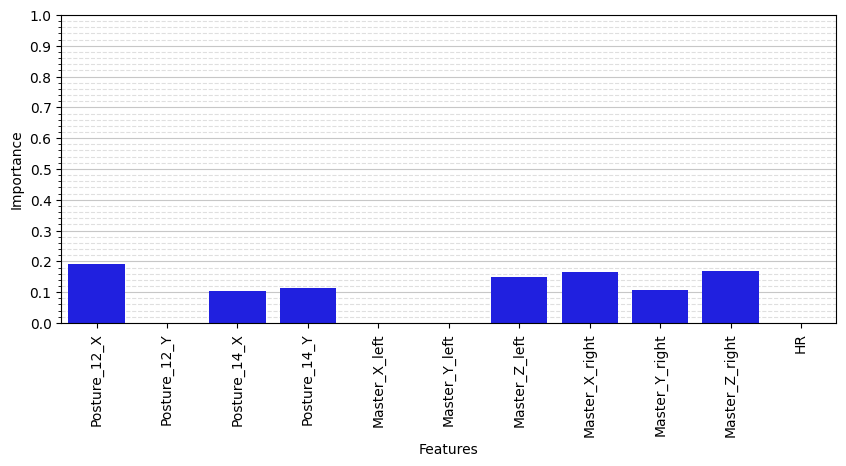

In [34]:
#Decision_tree_feature_importance2(model, features, bar_color, fig_size, sort, only_not_null, vertical)
pm.Decision_tree_feature_importance(DT_test, feature_names, "blue", (10,4), False, False, True)

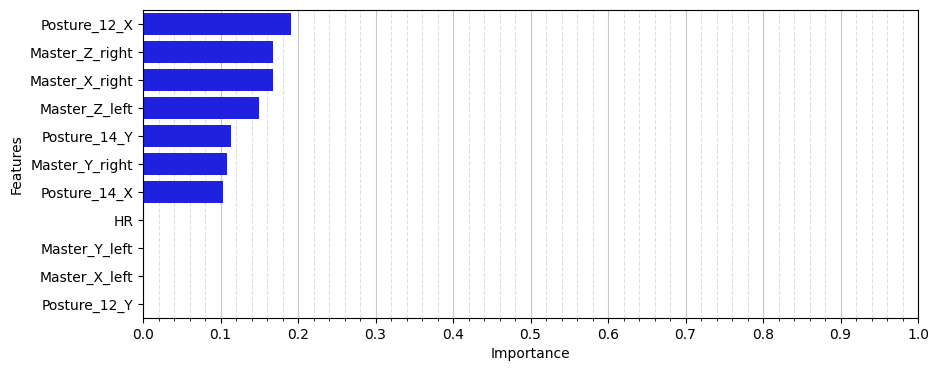

In [35]:
#Decision_tree_feature_importance(model, features, bar_color, fig_size, sort, only_not_null, vertical)
pm.Decision_tree_feature_importance(DT_test, feature_names, "blue", (10,4), True, False, False)

### 5.4. Cross-validation

In [42]:
#Cross_validation(model, X_train, Y_train, cv)
    #cv: int (fold number), "LOOCV"
Detection_mf_DT_model_3fold_ApEn = vrm.Cross_validation(DT_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, 3)
print("3-fold cross-validation: %s" %(Detection_mf_DT_model_3fold_ApEn))

Detection_mf_DT_model_loocv_ApEn = vrm.Cross_validation(DT_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, "LOOCV")
print("LOOCV: %s" %(Detection_mf_DT_model_loocv_ApEn))

3-fold cross-validation: 0.5833333333333334
LOOCV: 0.6176470588235294


In [43]:
#Explained_cross_validation(model, X_train, Y_train, cv)
    #cv: int (fold number), "LOOCV"
vrm.Explained_cross_validation(DT_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, 3)

Train: [12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33]  	 Validation: [ 0  1  2  3  4  5  6  7  8  9 10 11]
Train: [ 0  1  2  3  4  5  6  7  8  9 10 11 20 21 22 25 26 27 29 30 31 32 33]  	 Validation: [12 13 14 15 16 17 18 19 23 24 28]
Train: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 23 24 28]  	 Validation: [20 21 22 25 26 27 29 30 31 32 33]

Accuracies: [0.75, 0.45454545454545453, 0.5454545454545454]
Mean accuracy: 0.5833333333333334


In [44]:
vrm.Explained_cross_validation(DT_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, "LOOCV")

Train: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   Validation: [0]
Train: [ 0  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   Validation: [1]
Train: [ 0  1  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   Validation: [2]
Train: [ 0  1  2  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   Validation: [3]
Train: [ 0  1  2  3  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   Validation: [4]
Train: [ 0  1  2  3  4  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   Validation: [5]
Train: [ 0  1  2  3  4  5  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   Validation: [6]
Train: [ 0  1  2  3  4  5  6  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]   

---
# 6. Logistic Regression

In [45]:
LogR_model_ApEn_binary = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, True)
LogR_standardized_model_ApEn_binary = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, True)

LogR_model_ApEn_binary

LogisticRegression(C=2.0, max_iter=5000, random_state=0, solver='newton-cg')

In [46]:
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(LogR_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      1.00      0.80        10
           1       0.00      0.00      0.00         5

    accuracy                           0.67        15
   macro avg       0.33      0.50      0.40        15
weighted avg       0.44      0.67      0.53        15



In [47]:
vrm.Model_classification_report(LogR_standardized_model_ApEn_binary, Detection_standardized_mf_X_train_ApEn, Detection_standardized_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [1 0 0 1 0 0 0 0 0 1 1 0 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.64      0.70      0.67        10
           1       0.25      0.20      0.22         5

    accuracy                           0.53        15
   macro avg       0.44      0.45      0.44        15
weighted avg       0.51      0.53      0.52        15



### 6.2. Results checking

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
#Checking the results
model = LogisticRegression(random_state = 0, penalty = "l2", C = 2.0, solver = "newton-cg", max_iter = 5000)
model.fit(Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn)
model.score(Detection_mf_X_test_ApEn, Detection_mf_Y_test_ApEn)

0.6666666666666666

### 6.3. LR visualization

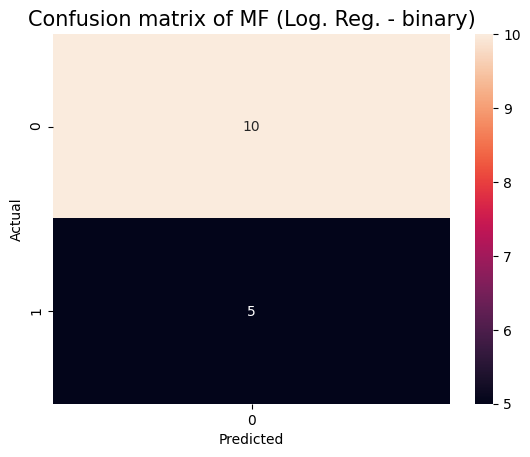

In [50]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of MF (Log. Reg. - binary)", LogR_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

### 6.4. Cross-validation

In [51]:
#Cross_validation(model, X_train, Y_train, cv)
    #cv: int (fold number), "LOOCV"
Detection_mf_LogR_model_3fold_ApEn = vrm.Cross_validation(LogR_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, 3)
print("3-fold cross-validation: %s" %(Detection_mf_LogR_model_3fold_ApEn))

Detection_mf_LogR_model_loocv_ApEn = vrm.Cross_validation(LogR_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, "LOOCV")
print("LOOCV: %s" %(Detection_mf_LogR_model_loocv_ApEn))

3-fold cross-validation: 0.6186868686868686
LOOCV: 0.5882352941176471


---
# 7. k-NN

In [52]:
#kNN(n_neighbors, weights, metric)
kNN_model_ApEn_binary = nts_cam.kNN(1, "distance", "euclidean")
kNN_standardized_model_ApEn_binary = nts_cam.kNN(1, "distance", "euclidean")

kNN_model_ApEn_binary

KNeighborsClassifier(metric='euclidean', n_neighbors=1, weights='distance')

In [53]:
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(kNN_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [0 1 0 0 1 0 1 1 0 0 1 0 0 1 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.62      0.50      0.56        10
           1       0.29      0.40      0.33         5

    accuracy                           0.47        15
   macro avg       0.46      0.45      0.44        15
weighted avg       0.51      0.47      0.48        15



In [54]:
vrm.Model_classification_report(kNN_standardized_model_ApEn_binary, Detection_standardized_mf_X_train_ApEn, Detection_standardized_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [1 1 0 0 1 0 1 1 0 0 1 0 0 1 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.57      0.40      0.47        10
           1       0.25      0.40      0.31         5

    accuracy                           0.40        15
   macro avg       0.41      0.40      0.39        15
weighted avg       0.46      0.40      0.42        15



### 7.2. Results checking

In [55]:
from sklearn.neighbors import KNeighborsClassifier

In [56]:
model = KNeighborsClassifier(metric="euclidean", n_neighbors=1, weights="distance")
model.fit(Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn)
model.score(Detection_mf_X_test_ApEn, Detection_mf_Y_test_ApEn)

0.4666666666666667

### 7.3. k-NN visualization

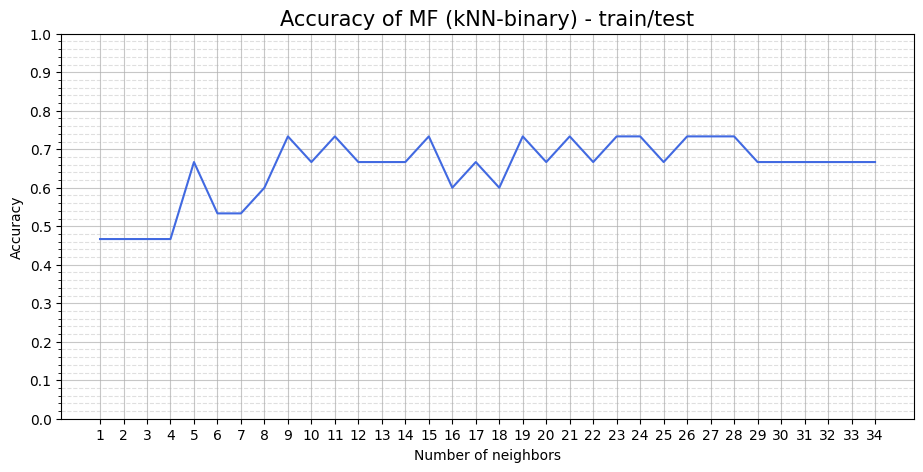

In [57]:
#kNN_k_values_plot(model, title, color, method, metric, metric_type, X_train, X_test, Y_train, Y_test, fig_size)
    #method: "train/test", "LOOCV", int for k-fold
    #metric: "accuracy", "precision", "recall", "f1-score"
    #metric_type: None, "macro", "weighted"wwwdw
        #accuracy: None
        #precision, recall, f1-score: "macro", "weighted"
kNN_model_visualization = nts_cam.kNN(1, "distance", "euclidean")
pm.kNN_k_values_plot(kNN_model_visualization, "Accuracy of MF (kNN-binary) - train/test", "royalblue", "train/test", "accuracy", None, \
                     Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn, (11,5))

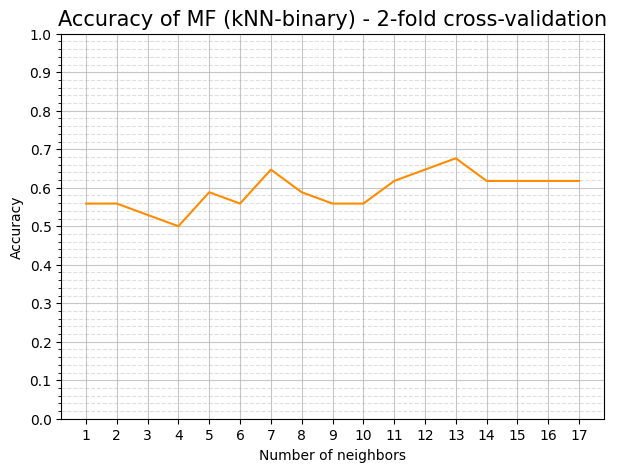

In [58]:
kNN_model_visualization = nts_cam.kNN(1, "distance", "euclidean")
pm.kNN_k_values_plot(kNN_model_visualization, "Accuracy of MF (kNN-binary) - 2-fold cross-validation", "darkorange", 2, "accuracy", None, \
                     Detection_standardized_mf_X_train_ApEn, Detection_standardized_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn, (7,5))

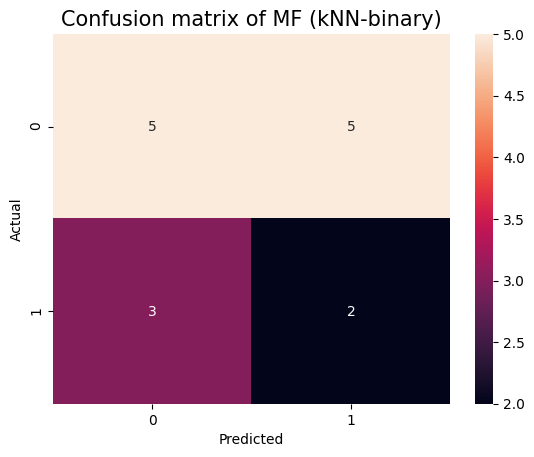

In [59]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of MF (kNN-binary)", kNN_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

### 7.4. Cross-validation

In [60]:
#Cross_validation(model, X_train, Y_train, cv)
    #cv: int (fold number), "LOOCV"
Detection_mf_kNN_model_3fold_ApEn = vrm.Cross_validation(kNN_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, 3)
print("3-fold cross-validation: %s" %(Detection_mf_kNN_model_3fold_ApEn))

Detection_mf_kNN_model_loocv_ApEn = vrm.Cross_validation(kNN_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, "LOOCV")
print("LOOCV: %s" %(Detection_mf_kNN_model_loocv_ApEn))

3-fold cross-validation: 0.4393939393939394
LOOCV: 0.47058823529411764


---
# 8. SVM

### 8.1. Model creation and traning-testing

In [61]:
#SVM(C, kernel, gamma, binary_class)
    #binary_class: True, False
        #True: binary classification
        #False: multiclass classification
        
SVM_model_ApEn_binary = nts_cam.SVM(2.0, "poly", 1.0, True)
SVM_standardized_model_ApEn_binary = nts_cam.SVM(2.0, "poly", 1.0, True)

SVM_model_ApEn_binary

SVC(C=2.0, gamma=1.0, kernel='poly', random_state=0)

In [62]:
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(SVM_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      1.00      0.80        10
           1       0.00      0.00      0.00         5

    accuracy                           0.67        15
   macro avg       0.33      0.50      0.40        15
weighted avg       0.44      0.67      0.53        15



In [63]:
vrm.Model_classification_report(SVM_standardized_model_ApEn_binary, Detection_standardized_mf_X_train_ApEn, Detection_standardized_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [1 1 0 1 1 0 1 1 0 1 0 1 0 1 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.60      0.30      0.40        10
           1       0.30      0.60      0.40         5

    accuracy                           0.40        15
   macro avg       0.45      0.45      0.40        15
weighted avg       0.50      0.40      0.40        15



### 8.2. Results checking

In [64]:
from sklearn import svm

In [65]:
#Checking the results
model = svm.SVC(C=2.0, gamma=1.0, kernel="poly", random_state=0)
model.fit(Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn)
model.score(Detection_mf_X_test_ApEn, Detection_mf_Y_test_ApEn)

0.6666666666666666

### 8.3. SVM visualization

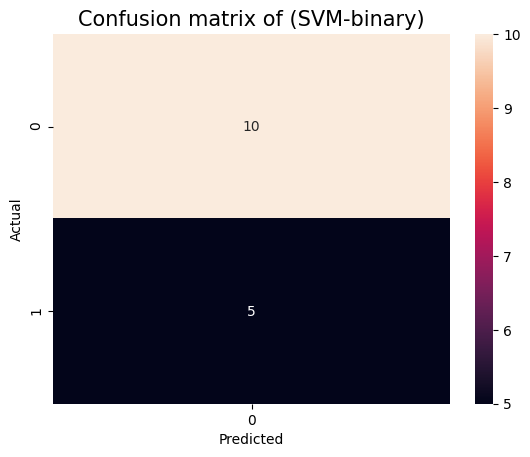

In [66]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of (SVM-binary)", SVM_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_X_test_ApEn, Detection_mf_Y_train_ApEn, Detection_mf_Y_test_ApEn)

### 8.4. Cross-validation

In [67]:
#Cross_validation(model, X_train, Y_train, cv)
    #cv: int (fold number), "LOOCV"
Detection_mf_SVM_model_3fold_ApEn = vrm.Cross_validation(SVM_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, 3)
print("3-fold cross-validation: %s" %(Detection_mf_SVM_model_3fold_ApEn))

Detection_mf_SVM_model_loocv_ApEn = vrm.Cross_validation(SVM_model_ApEn_binary, Detection_mf_X_train_ApEn, Detection_mf_Y_train_ApEn, "LOOCV")
print("LOOCV: %s" %(Detection_mf_SVM_model_loocv_ApEn))

3-fold cross-validation: 0.5883838383838383
LOOCV: 0.5588235294117647


---
# 9. Time series classification: k-NN with DTW
### 9.1. Data transformation

In [16]:
#TS_df_append_to_max_len(df_list, feature_names)
TS_Detection_df_list_max_len = dmm.TS_df_append_to_max_len(Detection_df_list, feature_names)

#TS_df_append_truncate_to_avg_len(df_list, feature_names)
TS_Detection_df_list_avg_len = dmm.TS_df_append_truncate_to_avg_len(Detection_df_list, feature_names)

#TS_df_truncate_to_min_len(df_list)
TS_Detection_df_list_min_len = dmm.TS_df_truncate_to_min_len(Detection_df_list)

The maximum length: 10835
The average length: 3234
The minimum length: 1633


In [18]:
TS_Detection_mf_Y_binary = dmm.TS_Y(Questionnaire, 3)
TS_Detection_pf_Y_binary = dmm.TS_Y(Questionnaire, 4)
TS_Detection_td_Y_binary = dmm.TS_Y(Questionnaire, 5)
TS_Detection_c_Y_binary = dmm.TS_Y(Questionnaire, 6)
TS_Detection_ss_Y_binary = dmm.TS_Y(Questionnaire, 7)
TS_Detection_d_Y_binary = dmm.TS_Y(Questionnaire, 8)

### 9.2. Train-test split

In [19]:
TS_Detection_X_train_max_len, TS_Detection_X_test_max_len, TS_Detection_mf_Y_train_max_len_binary, TS_Detection_mf_Y_test_max_len_binary = dmm.Train_test(TS_Detection_df_list_max_len, TS_Detection_mf_Y_binary, 0.3)
TS_Detection_X_train_max_len, TS_Detection_X_test_max_len, TS_Detection_pf_Y_train_max_len_binary, TS_Detection_pf_Y_test_max_len_binary = dmm.Train_test(TS_Detection_df_list_max_len, TS_Detection_pf_Y_binary, 0.3)
TS_Detection_X_train_max_len, TS_Detection_X_test_max_len, TS_Detection_td_Y_train_max_len_binary, TS_Detection_td_Y_test_max_len_binary = dmm.Train_test(TS_Detection_df_list_max_len, TS_Detection_td_Y_binary, 0.3)
TS_Detection_X_train_max_len, TS_Detection_X_test_max_len, TS_Detection_c_Y_train_max_len_binary, TS_Detection_c_Y_test_max_len_binary = dmm.Train_test(TS_Detection_df_list_max_len, TS_Detection_c_Y_binary, 0.3)
TS_Detection_X_train_max_len, TS_Detection_X_test_max_len, TS_Detection_ss_Y_train_max_len_binary, TS_Detection_ss_Y_test_max_len_binary = dmm.Train_test(TS_Detection_df_list_max_len, TS_Detection_ss_Y_binary, 0.3)
TS_Detection_X_train_max_len, TS_Detection_X_test_max_len, TS_Detection_d_Y_train_max_len_binary, TS_Detection_d_Y_test_max_len_binary = dmm.Train_test(TS_Detection_df_list_max_len, TS_Detection_d_Y_binary, 0.3)

TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len, TS_Detection_mf_Y_train_avg_len_binary, TS_Detection_mf_Y_test_avg_len_binary = dmm.Train_test(TS_Detection_df_list_avg_len, TS_Detection_mf_Y_binary, 0.3)
TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len, TS_Detection_pf_Y_train_avg_len_binary, TS_Detection_pf_Y_test_avg_len_binary = dmm.Train_test(TS_Detection_df_list_avg_len, TS_Detection_pf_Y_binary, 0.3)
TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len, TS_Detection_td_Y_train_avg_len_binary, TS_Detection_td_Y_test_avg_len_binary = dmm.Train_test(TS_Detection_df_list_avg_len, TS_Detection_td_Y_binary, 0.3)
TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len, TS_Detection_c_Y_train_avg_len_binary, TS_Detection_c_Y_test_avg_len_binary = dmm.Train_test(TS_Detection_df_list_avg_len, TS_Detection_c_Y_binary, 0.3)
TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len, TS_Detection_ss_Y_train_avg_len_binary, TS_Detection_ss_Y_test_avg_len_binary = dmm.Train_test(TS_Detection_df_list_avg_len, TS_Detection_ss_Y_binary, 0.3)
TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len, TS_Detection_d_Y_train_avg_len_binary, TS_Detection_d_Y_test_avg_len_binary = dmm.Train_test(TS_Detection_df_list_avg_len, TS_Detection_d_Y_binary, 0.3)

TS_Detection_X_train_min_len, TS_Detection_X_test_min_len, TS_Detection_mf_Y_train_min_len_binary, TS_Detection_mf_Y_test_min_len_binary = dmm.Train_test(TS_Detection_df_list_min_len, TS_Detection_mf_Y_binary, 0.3)
TS_Detection_X_train_min_len, TS_Detection_X_test_min_len, TS_Detection_pf_Y_train_min_len_binary, TS_Detection_pf_Y_test_min_len_binary = dmm.Train_test(TS_Detection_df_list_min_len, TS_Detection_pf_Y_binary, 0.3)
TS_Detection_X_train_min_len, TS_Detection_X_test_min_len, TS_Detection_td_Y_train_min_len_binary, TS_Detection_td_Y_test_min_len_binary = dmm.Train_test(TS_Detection_df_list_min_len, TS_Detection_td_Y_binary, 0.3)
TS_Detection_X_train_min_len, TS_Detection_X_test_min_len, TS_Detection_c_Y_train_min_len_binary, TS_Detection_c_Y_test_min_len_binary = dmm.Train_test(TS_Detection_df_list_min_len, TS_Detection_c_Y_binary, 0.3)
TS_Detection_X_train_min_len, TS_Detection_X_test_min_len, TS_Detection_ss_Y_train_min_len_binary, TS_Detection_ss_Y_test_min_len_binary = dmm.Train_test(TS_Detection_df_list_min_len, TS_Detection_ss_Y_binary, 0.3)
TS_Detection_X_train_min_len, TS_Detection_X_test_min_len, TS_Detection_d_Y_train_min_len_binary, TS_Detection_d_Y_test_min_len_binary = dmm.Train_test(TS_Detection_df_list_min_len, TS_Detection_d_Y_binary, 0.3)

### 9.3. Standardization

In [20]:
#TS_Standardization(X_train, X_test, feature_names)
TS_Detection_standardized_X_train_max_len, TS_Detection_standardized_X_test_max_len = dmm.TS_Standardization(TS_Detection_X_train_max_len, TS_Detection_X_test_max_len, feature_names)
TS_Detection_standardized_X_train_avg_len, TS_Detection_standardized_X_test_avg_len = dmm.TS_Standardization(TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len, feature_names)
TS_Detection_standardized_X_train_min_len, TS_Detection_standardized_X_test_min_len = dmm.TS_Standardization(TS_Detection_X_train_min_len, TS_Detection_X_test_min_len, feature_names)

### 9.4. Model creation and traning-testing

In [79]:
#TS_kNN_DTW_transform(X_train, X_test)
TS_kNN_DTW_Detection_X_train_max_len, TS_kNN_DTW_Detection_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_Detection_X_train_max_len, TS_Detection_X_test_max_len)
TS_kNN_DTW_Detection_X_train_avg_len, TS_kNN_DTW_Detection_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_Detection_X_train_avg_len, TS_Detection_X_test_avg_len)
TS_kNN_DTW_Detection_X_train_min_len, TS_kNN_DTW_Detection_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_Detection_X_train_min_len, TS_Detection_X_test_min_len)

TS_kNN_DTW_Detection_standardized_X_train_max_len, TS_kNN_DTW_Detection_standardized_X_test_max_len = dmm.TS_kNN_DTW_transform(TS_Detection_standardized_X_train_max_len, TS_Detection_standardized_X_test_max_len)
TS_kNN_DTW_Detection_standardized_X_train_avg_len, TS_kNN_DTW_Detection_standardized_X_test_avg_len = dmm.TS_kNN_DTW_transform(TS_Detection_standardized_X_train_avg_len, TS_Detection_standardized_X_test_avg_len)
TS_kNN_DTW_Detection_standardized_X_train_min_len, TS_kNN_DTW_Detection_standardized_X_test_min_len = dmm.TS_kNN_DTW_transform(TS_Detection_standardized_X_train_min_len, TS_Detection_standardized_X_test_min_len)

In [75]:
from Modules import ts_classification_algorithms_module as ts_cam

In [76]:
#TS_kNN_DTW(n_neighbors, weights)
TS_kNN_DTW_model_binary = ts_cam.TS_kNN_DTW(1, "uniform")
TS_kNN_DTW_standardized_model_binary = ts_cam.TS_kNN_DTW(1, "uniform")

TS_kNN_DTW_model_binary

KNeighborsTimeSeriesClassifier()

In [80]:
vrm.Model_classification_report(TS_kNN_DTW_model_binary, TS_kNN_DTW_Detection_X_train_min_len, TS_kNN_DTW_Detection_X_test_min_len, \
                                TS_Detection_mf_Y_train_min_len_binary, TS_Detection_mf_Y_test_min_len_binary)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [0 0 1 0 0 1 1 1 0 0 0 0 0 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        10
           1       0.60      0.60      0.60         5

    accuracy                           0.73        15
   macro avg       0.70      0.70      0.70        15
weighted avg       0.73      0.73      0.73        15



In [81]:
vrm.Model_classification_report(TS_kNN_DTW_standardized_model_binary, TS_kNN_DTW_Detection_standardized_X_train_min_len, TS_kNN_DTW_Detection_standardized_X_test_min_len, \
                                TS_Detection_mf_Y_train_min_len_binary, TS_Detection_mf_Y_test_min_len_binary)

Actual classes: [0 0 1 0 0 1 0 0 0 1 0 0 0 1 1], Predicted classes: [0 0 1 1 1 0 1 0 0 1 0 0 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.70      0.70      0.70        10
           1       0.40      0.40      0.40         5

    accuracy                           0.60        15
   macro avg       0.55      0.55      0.55        15
weighted avg       0.60      0.60      0.60        15



### 9.5. Results checking

In [82]:
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier

In [83]:
#Checking the results
model = KNeighborsTimeSeriesClassifier(n_neighbors = 1, weights =  "uniform")
model.fit(TS_kNN_DTW_Detection_X_train_min_len, TS_Detection_mf_Y_train_min_len_binary)
model.score(TS_kNN_DTW_Detection_X_test_min_len, TS_Detection_mf_Y_test_min_len_binary)

0.7333333333333333

### 9.6. Time series k-NN visualization

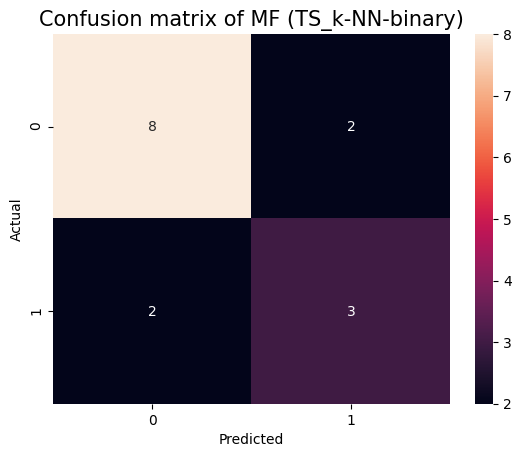

In [84]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of MF (TS_k-NN-binary)", TS_kNN_DTW_model_binary, TS_kNN_DTW_Detection_X_train_min_len, TS_kNN_DTW_Detection_X_test_min_len, \
                    TS_Detection_mf_Y_train_min_len_binary, TS_Detection_mf_Y_test_min_len_binary)

### 9.5. Cross-validation

In [85]:
TS_kNN_DTW_Detection_mf_model_3fold_ApEn = vrm.Cross_validation(TS_kNN_DTW_model_binary, TS_kNN_DTW_Detection_X_train_min_len, TS_Detection_mf_Y_train_min_len_binary, 3)
print("3-fold cross-validation: %s" %(TS_kNN_DTW_Detection_mf_model_3fold_ApEn))

TS_kNN_DTW_Detection_mf_model_loocv_ApEn = vrm.Cross_validation(TS_kNN_DTW_model_binary, TS_kNN_DTW_Detection_X_train_min_len, TS_Detection_mf_Y_train_min_len_binary, "LOOCV")
print("LOOCV: %s" %(TS_kNN_DTW_Detection_mf_model_loocv_ApEn))

3-fold cross-validation: 0.5
LOOCV: 0.5


----
## 10. Hyperparameter tuning (Non-time series)

In [26]:
from Modules import param_tuning_module as ptm
from Modules import validation_and_results_module as vrm
from Modules import plots_module as pm

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneOut

In [87]:
models = {
        'decision_tree': {
            'model': DecisionTreeClassifier(),
            'params': {
                'criterion':  ['gini', 'entropy'],
                'max_depth':  [None, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                'max_features': [None, 'sqrt', 'log2', 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
                'splitter': ['best', 'random'],
                'random_state': [0]
                     }
        },
        'k-NN': {
            'model': KNeighborsClassifier(),
            'params': {
                #+1: to included the last value in the range.
                'n_neighbors' : range(1, 5),
                'weights' : ['uniform', 'distance'],
                'metric' : ['euclidean', 'manhattan', 'minkowski']
                      }
        },
        'logistic_regression': {
            'model': LogisticRegression(),
            'params': {
                #Delete the comment before multi_class for multiclassification
                #'multi_class': ['ovr'], #For multiclass
                'penalty' : ["l1", "l2"],
                'solver' : ["newton-cg", "lbfgs", "liblinear", "sag", "saga"],
                'C':  [0.1, 0.5, 1, 5, 10, 50,  100, 500, 1000],
                #The maximum iteration value had to be increased (to 10000) due to convergence warnings.
                'max_iter': [10000],
                'random_state' : [0]
                    }
        },
        'SVM': {
            'model': svm.SVC(),
            'params': {
                #Delete the comment before multi_class for multiclassification
                #'decision_function_shape': ['ovo'], #For multiclass
                'C': [1000, 500, 100, 50, 10, 5, 1, 0.5, 0.1],
                'kernel' : ['poly', 'rbf', 'sigmoid', 'linear'],
                'gamma': ['auto', 'scale', 1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001],
                'random_state' : [0]
                       }
        
         }
}

In [88]:
test_size = [0.1, 0.2, 0.3, 0.4]

In [89]:
#Hyperparameter_tuning(models, metric, X, Y, test_sizes, cv, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
    #metric: "accuracy", "recall_micro", "recall_macro", "recall_weighted", "precision_micro", "precision_macro", "precision_weighted", "f1_micro", "f1_macro", "f1_weighted"
    #test_size: list
    #cv: int, LeaveOneOut()
    #standardize: "No", "Non-time"
    #calculate_maximum_neighbors: True, False
        #True: computes the maximum value of the neighbors and employs this value for model creation
    #show_results: True, False
    #n_jobs: int
mf_accuracy, mf_estimator = ptm.Hyperparameter_tuning(models, "f1_macro", Detection_mf_X_ApEn, Detection_mf_Y_ApEn, [0.3], 2, feature_names, "No", True, True, -1)

Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 17


,Model,Validation score,Test score,Parameter
0,decision_tree,0.802191,0.722222,"DecisionTreeClassifier(max_depth=3, max_features=0.1, random_state=0)"
1,k-NN,0.645833,0.659091,"KNeighborsClassifier(metric='manhattan', n_neighbors=4)"
2,logistic_regression,0.635714,0.444444,"LogisticRegression(C=100, max_iter=10000, penalty='l1', random_state=0,\n solver='saga')"
3,SVM,0.722894,0.550000,"SVC(C=5, kernel='poly', random_state=0)"


In [90]:
#Multiple_cv_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
mf_scores, mf_estimators, mf_cvs = ptm.Multiple_cv_hyperparameter_tuning(2, 13, models, "f1_macro", Detection_mf_X_ApEn, Detection_mf_Y_ApEn, [0.3] , feature_names, "No", True, False, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 17
CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 22
CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 25
CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 27
CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 28
CV: 7
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 29
CV: 8
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 29
CV: 9
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 30
CV: 10
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 30
CV: 11
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 3

In [91]:
#Best_param_tuning_accuracies(acc, estimator, cvs, test_size, class_alg)
mf_best_scores = dmm.Best_hyperparameter_tuning_scores(mf_scores, mf_estimators, mf_cvs, [0.3], ['Decision Tree', 'k-NN', 'Logistic Regression', 'SVM'])

Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Best cv
0,Decision Tree,0.722222,"DecisionTreeClassifier(max_depth=3, max_features=0.1, random_state=0)",2
1,k-NN,0.659091,"KNeighborsClassifier(metric='manhattan', n_neighbors=4)",2
2,Logistic Regression,0.444444,"LogisticRegression(C=100, max_iter=10000, penalty='l1', random_state=0,\n solver='saga')",2
3,SVM,0.641148,"SVC(C=50, gamma=1, kernel='sigmoid', random_state=0)",11


----
## 11. Hyperparameter tuning (Time series k-NN)
#### The TS_gesture_kNN_DTW_transform is not needed because it is part of the Hyperparameter_tuning function

In [99]:
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier 

In [100]:
TS_model = {
        'Time_series_kNN': {
            'model': KNeighborsTimeSeriesClassifier(distance="dtw"), #n_jobs only makes it quicker a little bit
            'params': {
                #+1: to included the last value in the range.
                'n_neighbors' : range(1, 5),
                'weights' : ['uniform', 'distance']
                      }
               }
           }

In [101]:
test_size = [0.1, 0.2, 0.3, 0.4]

In [102]:
#Hyperparameter_tuning(models, metric, X, Y, test_sizes, cv, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
TS_mf_score, TS_mf_estimator = ptm.Hyperparameter_tuning(TS_model, "f1_macro", TS_Detection_df_list_min_len, TS_Detection_mf_Y_binary, [0.3], 2, feature_names, "No", True, True, -1)

Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 17


,Model,Validation score,Test score,Parameter
0,Time_series_kNN,0.567571,0.761905,KNeighborsTimeSeriesClassifier(n_neighbors=3)


In [107]:
#Multiple_cv_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
TS_mf_scores, TS_mf_estimators, TS_mf_cvs = ptm.Multiple_cv_hyperparameter_tuning(2, 13, TS_model, "f1_macro",TS_Detection_df_list_min_len, TS_Detection_mf_Y_binary, [0.3], feature_names, "No", True, False, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 17
CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 22
CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 25
CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 27
CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 28
CV: 7
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 29
CV: 8
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 29
CV: 9
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 30
CV: 10
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 30
CV: 11
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 3

In [109]:
#Best_param_tuning_accuracies(acc, estimator, cvs, test_size, class_alg)
TS_mf_best_scores = dmm.Best_hyperparameter_tuning_scores(TS_mf_scores, TS_mf_estimators, TS_mf_cvs, [0.3], ['Time_series_kNN'])

Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Best cv
0,Time_series_kNN,0.761905,KNeighborsTimeSeriesClassifier(n_neighbors=3),2


---
## 12. Dimensionality reduction with feature selection before the hyperparameter tuning (non-time series classifier)

In [115]:
from Modules import dim_reduction_module as drm
from sklearn.feature_selection import mutual_info_classif as MIC

In [116]:
test_size = [0.1, 0.2, 0.3, 0.4]

In [117]:
#MIC_dimRed_and_hyperparameter_tuning(models, metric, X, Y, test_sizes, cv, MIC_step, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
mf_score_dimRed, mf_estimator_dimRed, mf_feature_dimRed, mf_threshold_dimRed = drm.MIC_dimRed_and_hyperparameter_tuning(models, "f1_macro", Detection_mf_X_ApEn, Detection_mf_Y_ApEn, [0.3], 2, 0.01, \
                                                                                                                        feature_names, "No", True, True, -1)

Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 17


,Model,Validation score,Test score,Parameter,Features,MIC_threshold
0,decision_tree,0.802191,0.722222,"DecisionTreeClassifier(max_depth=3, max_features=0.1, random_state=0)","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",0.00
1,k-NN,0.736905,0.722222,"KNeighborsClassifier(metric='manhattan', n_neighbors=7)","[2, 3]",0.05
2,logistic_regression,0.613636,0.700000,"LogisticRegression(C=500, max_iter=10000, random_state=0, solver='newton-cg')","[2, 3, 5]",0.01
3,SVM,0.654932,0.700000,"SVC(C=50, gamma=1, kernel='sigmoid', random_state=0)","[2, 3, 5]",0.01


In [120]:
#Multiple_cv_MIC_dimRed_and_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, MIC_step, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
mf_scores_dimRed, mf_estimators_dimRed, mf_features_dimRed, mf_thresholds_dimRed, mf_cvs_dimRed = \
    drm.Multiple_cv_MIC_dimRed_and_hyperparameter_tuning(2, 13, models, "f1_macro", Detection_mf_X_ApEn, Detection_mf_Y_ApEn, [0.3], 0.01, feature_names, "No", True, False, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 17
CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 22
CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 25
CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 27
CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 28
CV: 7
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 29
CV: 8
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 29
CV: 9
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 30
CV: 10
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 30
CV: 11
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 3

In [121]:
dmm.Best_dimRed_hyperparameter_tuning_scores(mf_scores_dimRed, mf_estimators_dimRed, mf_features_dimRed, mf_thresholds_dimRed, mf_cvs_dimRed, [0.3], ['Decision Tree', 'k-NN', 'Logistic Regression', 'SVM'])

Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Features,MIC_threshold,Best cv
0,Decision Tree,0.784689,"DecisionTreeClassifier(max_depth=7, max_features='sqrt', random_state=0,\n splitter='random')","[2, 3]",0.05,8
1,k-NN,0.732143,"KNeighborsClassifier(metric='euclidean', n_neighbors=7)","[2, 3, 5]",0.01,9
2,Logistic Regression,0.700000,"LogisticRegression(C=500, max_iter=10000, random_state=0, solver='newton-cg')","[2, 3, 5]",0.01,2
3,SVM,0.700000,"SVC(C=50, gamma=1, kernel='sigmoid', random_state=0)","[2, 3, 5]",0.01,2


---
## 13. Hyperparameter tuning (NN)

In [22]:
#diasble gpu usage, beacuse of an error
from Modules import ts_classification_algorithms_module as ts_cam
import tensorflow as tf
import os
from tensorflow import keras
%set_env TF_ENABLE_ONEDNN_OPTS=0
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

env: TF_ENABLE_ONEDNN_OPTS=0


In [23]:
from itertools import product

activations = ["relu", "elu"]
dropouts = [0.2, 0.3]
filters_list = [16, 32]
kernel_sizes = [3, 5]

param_grid = list(product(activations, dropouts, filters_list, kernel_sizes))
param_grid

[('relu', 0.2, 16, 3),
 ('relu', 0.2, 16, 5),
 ('relu', 0.2, 32, 3),
 ('relu', 0.2, 32, 5),
 ('relu', 0.3, 16, 3),
 ('relu', 0.3, 16, 5),
 ('relu', 0.3, 32, 3),
 ('relu', 0.3, 32, 5),
 ('elu', 0.2, 16, 3),
 ('elu', 0.2, 16, 5),
 ('elu', 0.2, 32, 3),
 ('elu', 0.2, 32, 5),
 ('elu', 0.3, 16, 3),
 ('elu', 0.3, 16, 5),
 ('elu', 0.3, 32, 3),
 ('elu', 0.3, 32, 5)]

In [28]:
#Hyperparameter_tuning_NN(X, Y, param_grid, epoch, batch_size, num_class, metric, validation_split, standardize, feature_names)
result = ptm.Hyperparameter_tuning_NN(TS_Detection_df_list_min_len, TS_Detection_mf_Y_binary, param_grid, 100, 10, 2, "binary_accuracy", 0.3, "No", feature_names)

Futtatás 1/16: relu, 0.2, 16, 3
Restoring model weights from the end of the best epoch: 7.
Epoch 12: early stopping
1/1 [==============================] - 0s 220ms/step - loss: 0.9949 - binary_accuracy: 0.3333
Futtatás 2/16: relu, 0.2, 16, 5
Restoring model weights from the end of the best epoch: 1.
Epoch 6: early stopping
1/1 [==============================] - 0s 223ms/step - loss: 1.1693 - binary_accuracy: 0.3333
Futtatás 3/16: relu, 0.2, 32, 3
Restoring model weights from the end of the best epoch: 4.
Epoch 9: early stopping
1/1 [==============================] - 0s 238ms/step - loss: 0.6395 - binary_accuracy: 0.6667
Futtatás 4/16: relu, 0.2, 32, 5
Restoring model weights from the end of the best epoch: 4.
Epoch 9: early stopping
1/1 [==============================] - 0s 266ms/step - loss: 0.6461 - binary_accuracy: 0.6000
Futtatás 5/16: relu, 0.3, 16, 3
Restoring model weights from the end of the best epoch: 6.
Epoch 11: early stopping
1/1 [==============================] - 0s 204ms

In [29]:
result

,activation,dropout,filters,kernel,test_acc
0,relu,0.2,16,3,0.333333
1,relu,0.2,16,5,0.333333
2,relu,0.2,32,3,0.666667
3,relu,0.2,32,5,0.600000
4,relu,0.3,16,3,0.333333
5,relu,0.3,16,5,0.333333
6,relu,0.3,32,3,0.333333
7,relu,0.3,32,5,0.600000
8,elu,0.2,16,3,0.333333
9,elu,0.2,16,5,0.333333
